# Randomized Search temporal — Lending Club

Este notebook realiza **una única búsqueda aleatoria** de hiperparámetros para regresión logística, SVM lineal y Gradient Boosting, usando las 26 predictoras seleccionadas en la exploración final. Selecciona configuraciones por ROC-AUC promedio; Average Precision (PR-AUC) y el desempeño por año sirven como complemento. La búsqueda es limitada a las combinaciones aleatorias muestreadas y no pretende hallar un óptimo universal.

## 1. Validación temporal expansiva

Cada configuración se evalúa en los mismos cuatro cortes, sin mezclar filas entre años:

| Corte | Entrenamiento | Validación |
|---|---|---|
| 1 | 2007–2012 | 2013 |
| 2 | 2007–2013 | 2014 |
| 3 | 2007–2014 | 2015 |
| 4 | 2007–2015 | 2016 |

`RandomizedSearchCV` recibe explícitamente estos índices de entrenamiento y validación. La selección de hiperparámetros es aleatoria; **la partición de observaciones no lo es**. 2017 en adelante no se incluye en los datos de búsqueda. El preprocesamiento está dentro de un `Pipeline`: la mediana, el One-Hot y el escalado se ajustan de nuevo solo con el entrenamiento de cada corte y luego se aplican a su año de validación. Usamos mediana sola, igual que la comparación base de 07, porque añadir indicadores no cambió materialmente ROC-AUC.

## 2. Cargar las 26 predictoras y formar los cortes

In [1]:
from pathlib import Path
import sys
import time
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import localizar_datos, SEMILLA
from src.modelado import cargar_datos_modelado

archivo = localizar_datos()
inicio = time.perf_counter()
datos, predictoras = cargar_datos_modelado(archivo)
print("Predictoras cargadas:", len(predictoras))
assert len(predictoras) == 26
print(f"Carga y selección: {time.perf_counter() - inicio:.1f} s")

# Se excluye la prueba antes de preparar X e y para la búsqueda.
mascara_desarrollo = datos["anio"] <= 2016
datos_cv = datos.loc[mascara_desarrollo].copy()
X_cv = datos_cv[predictoras].copy()
y_cv = datos_cv["default"].astype("int8").copy()

# La fecha absoluta se convierte en antigüedad crediticia; es una transformación por fila,
# no aprende estadísticas de validación ni de prueba.
if "earliest_cr_line" in X_cv.columns:
    fecha_otorgamiento = datos_cv["fecha_prestamo"]
    fecha_inicio = X_cv["earliest_cr_line"]
    X_cv["meses_desde_earliest_cr_line"] = (
        (fecha_otorgamiento.dt.year - fecha_inicio.dt.year) * 12
        + (fecha_otorgamiento.dt.month - fecha_inicio.dt.month)
    ).astype("float64")
    X_cv = X_cv.drop(columns="earliest_cr_line")

# Normalizamos tipos para el preprocesador y tratamos infinitos como faltantes.
for columna in X_cv.columns:
    if pd.api.types.is_numeric_dtype(X_cv[columna]):
        X_cv[columna] = pd.to_numeric(X_cv[columna], errors="coerce").astype("float64")
        X_cv[columna] = X_cv[columna].replace([np.inf, -np.inf], np.nan)
    else:
        X_cv[columna] = X_cv[columna].astype(object).where(X_cv[columna].notna(), np.nan)

anios_validacion = [2013, 2014, 2015, 2016]
cv_temporal = []
filas_cortes = []
anios_cv = datos_cv["anio"].to_numpy()
for anio_validacion in anios_validacion:
    indices_train = np.flatnonzero(anios_cv < anio_validacion)
    indices_valid = np.flatnonzero(anios_cv == anio_validacion)
    if len(indices_train) == 0 or len(indices_valid) == 0:
        raise ValueError(f"Corte vacío para validación {anio_validacion}.")
    if datos_cv.iloc[indices_train]["anio"].max() >= anio_validacion:
        raise AssertionError("Se detectó mezcla temporal entre entrenamiento y validación.")
    cv_temporal.append((indices_train, indices_valid))
    filas_cortes.append({
        "corte": f"entrenamiento hasta {anio_validacion - 1} / validación {anio_validacion}",
        "filas_entrenamiento": len(indices_train),
        "filas_validación": len(indices_valid),
        "tasa_incumplimiento_validación_pct": float(y_cv.iloc[indices_valid].mean() * 100),
    })

tabla_cortes = pd.DataFrame(filas_cortes)
display(tabla_cortes)
print("Años de validación incluidos:", sorted(datos_cv.iloc[np.concatenate([s[1] for s in cv_temporal])]["anio"].unique()))
print("Años de prueba presentes en X/y de búsqueda:", sorted(set(datos.loc[datos["anio"] >= 2017, "anio"].unique()) & set(datos_cv["anio"].unique())))

Selección por faltantes hasta 2012 (<10%): 26 conservadas de 95; 69 excluidas.
Predictoras cargadas: 26
Carga y selección: 98.9 s


,corte,filas_entrenamiento,filas_validación,tasa_incumplimiento_validación_pct
0,entrenamiento hasta 2012 / validación 2013,93153,134804,15.595976
1,entrenamiento hasta 2013 / validación 2014,227957,223102,18.449409
2,entrenamiento hasta 2014 / validación 2015,451059,375545,20.184798
3,entrenamiento hasta 2015 / validación 2016,826604,293095,23.283236


Años de validación incluidos: [np.int16(2013), np.int16(2014), np.int16(2015), np.int16(2016)]
Años de prueba presentes en X/y de búsqueda: []


## 3. Referencia: configuraciones originales

Usamos las métricas de 07 para las configuraciones iniciales, con las mismas 26 variables, los mismos cuatro años y mediana sola. Esto evita volver a entrenar los baselines y permite compararlos con las configuraciones elegidas por Randomized Search.

In [2]:
ruta_baseline = RAIZ / "outputs" / "entrenamiento_26_variables" / "metricas_validacion_temporal.csv"
if not ruta_baseline.exists():
    raise FileNotFoundError(f"No se encontró el baseline de 26 variables: {ruta_baseline}")
baseline_por_anio = pd.read_csv(ruta_baseline, encoding="utf-8-sig")
baseline_por_anio = baseline_por_anio.loc[
    (~baseline_por_anio["indicadores_faltantes"])
    & baseline_por_anio["modelo"].isin(["regresion_logistica", "svm_lineal", "gradient_boosting"])
].copy()
assert set(baseline_por_anio["anio_validacion"]) == set(anios_validacion)
baseline_resumen = (baseline_por_anio.groupby("modelo", as_index=False)
    .agg(
        ROC_AUC_baseline=("roc_auc", "mean"),
        ROC_AUC_std_baseline=("roc_auc", "std"),
        PR_AUC_baseline=("pr_auc", "mean"),
        PR_AUC_std_baseline=("pr_auc", "std"),
    ))
baseline_resumen["ROC_AUC_std_baseline"] = baseline_por_anio.groupby("modelo")["roc_auc"].std(ddof=0).to_numpy()
baseline_resumen["PR_AUC_std_baseline"] = baseline_por_anio.groupby("modelo")["pr_auc"].std(ddof=0).to_numpy()
print("Resultados originales por modelo:")
display(baseline_resumen.round(4))
print("Resultados originales por año:")
display(baseline_por_anio[["modelo", "anio_validacion", "roc_auc", "pr_auc"]]
        .sort_values(["modelo", "anio_validacion"]).round(4))

Resultados originales por modelo:


,modelo,ROC_AUC_baseline,ROC_AUC_std_baseline,PR_AUC_baseline,PR_AUC_std_baseline
0,gradient_boosting,0.6954,0.0149,0.3509,0.0547
1,regresion_logistica,0.6925,0.0159,0.3481,0.0562
2,svm_lineal,0.6916,0.0167,0.3464,0.0569


Resultados originales por año:


,modelo,anio_validacion,roc_auc,pr_auc
4,gradient_boosting,2013,0.6746,0.2667
9,gradient_boosting,2014,0.6976,0.3384
14,gradient_boosting,2015,0.7163,0.3953
19,gradient_boosting,2016,0.6929,0.4032
1,regresion_logistica,2013,0.6690,0.2618
6,regresion_logistica,2014,0.6948,0.3346
11,regresion_logistica,2015,0.7138,0.3938
16,regresion_logistica,2016,0.6924,0.4021
2,svm_lineal,2013,0.6673,0.2583
7,svm_lineal,2014,0.6953,0.3341


## 4. Modelos y espacios aleatorios

Se conservan las tres familias con mejor resultado inicial: regresión logística, SVM lineal y Gradient Boosting. Por cada familia se sortean **10 combinaciones** con una semilla fija. `C` se toma en escala logarítmica; para Gradient Boosting se sortean tasa de aprendizaje, iteraciones, hojas, tamaño mínimo de hoja y regularización. `refit=False` evita entrenar automáticamente un modelo final con todo el desarrollo: aquí solo comparamos configuraciones. ROC-AUC es el criterio de selección; PR-AUC se reporta por separado.

In [3]:
numericas = [c for c in X_cv.columns if pd.api.types.is_numeric_dtype(X_cv[c])]
categoricas = [c for c in X_cv.columns if c not in numericas]
print("Predictoras numéricas:", len(numericas), "| categóricas:", len(categoricas))


def crear_preprocesador(salida_densa=False):
    """Imputa, codifica y escala dentro del fold donde se ajusta el pipeline."""
    transformadores = []
    if numericas:
        pipeline_numericas = Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler(with_mean=salida_densa)),
        ])
        transformadores.append(("numericas", pipeline_numericas, numericas))
    if categoricas:
        pipeline_categoricas = Pipeline([
            ("imputar", SimpleImputer(strategy="constant", fill_value="Sin información")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore", drop="first",
                sparse_output=not salida_densa, dtype=np.float32,
            )),
        ])
        transformadores.append(("categoricas", pipeline_categoricas, categoricas))
    return ColumnTransformer(
        transformadores,
        remainder="drop",
        sparse_threshold=0.0 if salida_densa else 1.0,
    )


modelos_base = {
    "regresion_logistica": LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=2000, random_state=SEMILLA,
    ),
    "svm_lineal": LinearSVC(
        C=1.0, class_weight=None, dual="auto", max_iter=5000,
        random_state=SEMILLA,
    ),
    "gradient_boosting": HistGradientBoostingClassifier(
        max_iter=75, max_leaf_nodes=15, learning_rate=0.08,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=SEMILLA,
    ),
}

# Espacios de muestreo; cada búsqueda evalúa 10 sorteos sobre los mismos 4 cortes.
espacios_parametros = {
    "regresion_logistica": {
        "modelo__C": loguniform(0.01, 10.0),
        "modelo__class_weight": [None, "balanced"],
    },
    "svm_lineal": {
        "modelo__C": loguniform(0.01, 10.0),
        "modelo__class_weight": [None, "balanced"],
    },
    "gradient_boosting": {
        "modelo__learning_rate": loguniform(0.03, 0.20),
        "modelo__max_iter": randint(75, 201),
        "modelo__max_leaf_nodes": randint(7, 33),
        "modelo__min_samples_leaf": randint(20, 61),
        "modelo__l2_regularization": loguniform(0.1, 5.0),
    },
}
N_ITER = 10
print("Sorteos por modelo:", N_ITER, "| familias:", len(modelos_base), "| total de configuraciones sorteadas:", N_ITER * len(modelos_base))

Predictoras numéricas: 20 | categóricas: 6
Sorteos por modelo: 10 | familias: 3 | total de configuraciones sorteadas: 30


## 5. Ejecutar Randomized Search con ROC-AUC y PR-AUC

In [4]:
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
resultados_busqueda = []
resumen_busqueda = []
inicio_busqueda = time.perf_counter()

for nombre_modelo, estimador_base in modelos_base.items():
    es_gradient = nombre_modelo == "gradient_boosting"
    pipeline = Pipeline([
        ("preprocesar", crear_preprocesador(salida_densa=es_gradient)),
        ("modelo", estimador_base),
    ])
    busqueda = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=espacios_parametros[nombre_modelo],
        n_iter=N_ITER,
        scoring=scoring,
        refit=False,
        cv=cv_temporal,
        random_state=SEMILLA,
        n_jobs=1,
        pre_dispatch=1,
        return_train_score=False,
        error_score="raise",
        verbose=0,
    )
    inicio_modelo = time.perf_counter()
    busqueda.fit(X_cv, y_cv)
    segundos_modelo = time.perf_counter() - inicio_modelo
    cv_resultados = busqueda.cv_results_

    for indice, parametros in enumerate(cv_resultados["params"]):
        parametros_modelo = {k.replace("modelo__", ""): v for k, v in parametros.items()}
        parametros_json = json.dumps(parametros_modelo, ensure_ascii=False, sort_keys=True, default=str)
        for numero_corte, anio_validacion in enumerate(anios_validacion):
            resultados_busqueda.append({
                "modelo": nombre_modelo,
                "configuracion": indice + 1,
                "hiperparametros": parametros_json,
                "anio_validacion": anio_validacion,
                "ROC_AUC": float(cv_resultados[f"split{numero_corte}_test_roc_auc"][indice]),
                "PR_AUC": float(cv_resultados[f"split{numero_corte}_test_pr_auc"][indice]),
            })

    mejores_indices = np.argsort(cv_resultados["mean_test_roc_auc"])[::-1]
    for indice in mejores_indices:
        parametros_modelo = {k.replace("modelo__", ""): v for k, v in cv_resultados["params"][indice].items()}
        resumen_busqueda.append({
            "modelo": nombre_modelo,
            "configuracion": int(indice + 1),
            "hiperparametros": json.dumps(parametros_modelo, ensure_ascii=False, sort_keys=True, default=str),
            "ROC_AUC_promedio": float(cv_resultados["mean_test_roc_auc"][indice]),
            "ROC_AUC_variabilidad": float(cv_resultados["std_test_roc_auc"][indice]),
            "PR_AUC_promedio": float(cv_resultados["mean_test_pr_auc"][indice]),
            "PR_AUC_variabilidad": float(cv_resultados["std_test_pr_auc"][indice]),
            "segundos_promedio_ajuste": float(cv_resultados["mean_fit_time"][indice]),
            "rango_ROC_AUC": int(cv_resultados["rank_test_roc_auc"][indice]),
        })
    print(f"{nombre_modelo}: {N_ITER} sorteos × 4 cortes listos en {segundos_modelo / 60:.1f} min.", flush=True)
    del busqueda, pipeline, cv_resultados
    gc.collect()

resultados_busqueda = pd.DataFrame(resultados_busqueda)
resumen_busqueda = pd.DataFrame(resumen_busqueda).sort_values(
    ["modelo", "ROC_AUC_promedio", "PR_AUC_promedio"],
    ascending=[True, False, False],
).reset_index(drop=True)
mejores_busqueda = resumen_busqueda
mejores_busqueda = (mejores_busqueda.sort_values(
    ["modelo", "ROC_AUC_promedio", "PR_AUC_promedio"],
    ascending=[True, False, False],
).groupby("modelo", as_index=False).first())
tiempo_busqueda = time.perf_counter() - inicio_busqueda
assert set(resultados_busqueda["anio_validacion"].unique()) == set(anios_validacion)
print(f"Total: {len(resumen_busqueda)} configuraciones aleatorias y {len(resultados_busqueda)} resultados por configuración-año.")
print(f"Tiempo total de búsqueda: {tiempo_busqueda / 60:.1f} minutos.")
print("La selección se basa en ROC-AUC promedio; no se optimizó el umbral ni se evaluó calibración.")

C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


... (54 outputs left out)

C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


gradient_boosting: 10 sorteos × 4 cortes listos en 9.4 min.


Total: 30 configuraciones aleatorias y 120 resultados por configuración-año.
Tiempo total de búsqueda: 46.0 minutos.
La selección se basa en ROC-AUC promedio; no se optimizó el umbral ni se evaluó calibración.


## 6. Comparar configuraciones seleccionadas con el entrenamiento original

Original frente a la mejor configuración sorteada por modelo:


,modelo,hiperparametros,ROC_AUC_baseline,ROC_AUC_randomized,diferencia_ROC_AUC,PR_AUC_baseline,PR_AUC_randomized,diferencia_PR_AUC,ROC_AUC_std_baseline,ROC_AUC_std_randomized
0,gradient_boosting,"{""l2_regularization"": 0.32877474139911184, ""le...",0.6954,0.7000,0.0046,0.3509,0.3551,0.0042,0.0149,0.0169
1,regresion_logistica,"{""C"": 0.13292918943162169, ""class_weight"": null}",0.6925,0.6927,0.0002,0.3481,0.3484,0.0004,0.0159,0.0157
2,svm_lineal,"{""C"": 0.010053940194693016, ""class_weight"": ""b...",0.6916,0.6926,0.0009,0.3464,0.3477,0.0013,0.0167,0.0160


Resultados por año para las configuraciones seleccionadas:


,modelo,anio_validacion,ROC_AUC_original,ROC_AUC_randomized,PR_AUC_original,PR_AUC_randomized
0,gradient_boosting,2013,0.6746,0.6746,0.2667,0.2650
1,gradient_boosting,2014,0.6976,0.6999,0.3384,0.3386
2,gradient_boosting,2015,0.7163,0.7220,0.3953,0.4016
3,gradient_boosting,2016,0.6929,0.7035,0.4032,0.4152
4,regresion_logistica,2013,0.6690,0.6697,0.2618,0.2631
5,regresion_logistica,2014,0.6948,0.6949,0.3346,0.3345
6,regresion_logistica,2015,0.7138,0.7139,0.3938,0.3940
7,regresion_logistica,2016,0.6924,0.6924,0.4021,0.4022
8,svm_lineal,2013,0.6673,0.6694,0.2583,0.2623
9,svm_lineal,2014,0.6953,0.6950,0.3341,0.3340


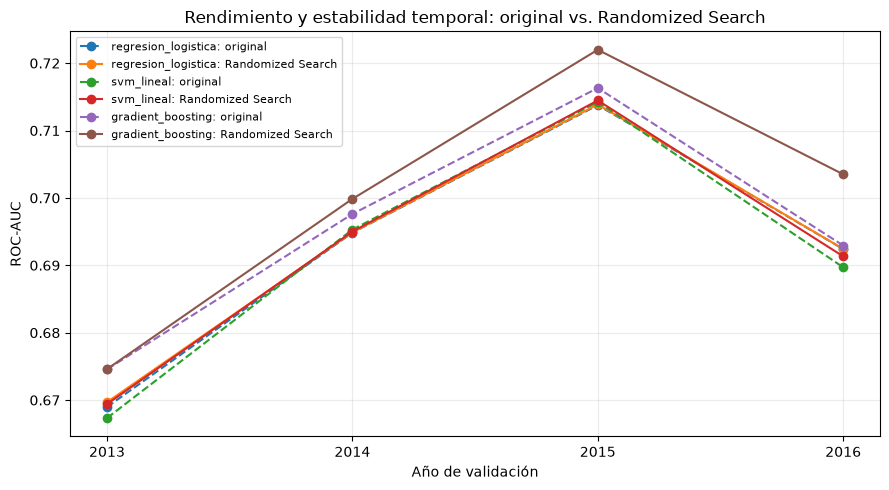

Tablas guardadas en: C:\Users\josue\Proyecto-ML-Grupo8\outputs\hiperparametros_randomized_26_variables
No se usaron filas desde 2017 para seleccionar ni evaluar hiperparámetros.


In [5]:
comparacion = baseline_resumen.merge(
    mejores_busqueda[[
        "modelo", "configuracion", "hiperparametros", "ROC_AUC_promedio",
        "ROC_AUC_variabilidad", "PR_AUC_promedio", "PR_AUC_variabilidad",
    ]],
    on="modelo", how="inner",
)
comparacion["diferencia_ROC_AUC"] = comparacion["ROC_AUC_promedio"] - comparacion["ROC_AUC_baseline"]
comparacion["diferencia_PR_AUC"] = comparacion["PR_AUC_promedio"] - comparacion["PR_AUC_baseline"]
comparacion = comparacion.rename(columns={
    "ROC_AUC_promedio": "ROC_AUC_randomized",
    "ROC_AUC_variabilidad": "ROC_AUC_std_randomized",
    "PR_AUC_promedio": "PR_AUC_randomized",
    "PR_AUC_variabilidad": "PR_AUC_std_randomized",
})
print("Original frente a la mejor configuración sorteada por modelo:")
display(comparacion[[
    "modelo", "hiperparametros", "ROC_AUC_baseline", "ROC_AUC_randomized",
    "diferencia_ROC_AUC", "PR_AUC_baseline", "PR_AUC_randomized",
    "diferencia_PR_AUC", "ROC_AUC_std_baseline", "ROC_AUC_std_randomized",
]].round(4))

# Tabla anual: referencia original y configuración aleatoria elegida.
filas_por_anio = []
for _, mejor in mejores_busqueda.iterrows():
    m = mejor["modelo"]
    numero_config = int(mejor["configuracion"])
    base_m = baseline_por_anio.loc[baseline_por_anio["modelo"] == m]
    nueva_m = resultados_busqueda.loc[
        (resultados_busqueda["modelo"] == m)
        & (resultados_busqueda["configuracion"] == numero_config)
    ]
    for anio_validacion in anios_validacion:
        base_fila = base_m.loc[base_m["anio_validacion"] == anio_validacion].iloc[0]
        nueva_fila = nueva_m.loc[nueva_m["anio_validacion"] == anio_validacion].iloc[0]
        filas_por_anio.append({
            "modelo": m,
            "anio_validacion": anio_validacion,
            "ROC_AUC_original": base_fila["roc_auc"],
            "ROC_AUC_randomized": nueva_fila["ROC_AUC"],
            "PR_AUC_original": base_fila["pr_auc"],
            "PR_AUC_randomized": nueva_fila["PR_AUC"],
        })
comparacion_por_anio = pd.DataFrame(filas_por_anio)
print("Resultados por año para las configuraciones seleccionadas:")
display(comparacion_por_anio.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
for modelo in modelos_base:
    datos_grafico = comparacion_por_anio.loc[comparacion_por_anio["modelo"] == modelo]
    ax.plot(datos_grafico["anio_validacion"], datos_grafico["ROC_AUC_original"],
            marker="o", linestyle="--", label=f"{modelo}: original")
    ax.plot(datos_grafico["anio_validacion"], datos_grafico["ROC_AUC_randomized"],
            marker="o", label=f"{modelo}: Randomized Search")
ax.set_xticks(anios_validacion)
ax.set_xlabel("Año de validación")
ax.set_ylabel("ROC-AUC")
ax.set_title("Rendimiento y estabilidad temporal: original vs. Randomized Search")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

salida = RAIZ / "outputs" / "hiperparametros_randomized_26_variables"
salida.mkdir(parents=True, exist_ok=True)
resultados_busqueda.to_csv(salida / "resultados_randomized_por_anio.csv", index=False, encoding="utf-8-sig")
resumen_busqueda.to_csv(salida / "resumen_configuraciones_randomized.csv", index=False, encoding="utf-8-sig")
mejores_busqueda.to_csv(salida / "mejores_parametros_por_modelo.csv", index=False, encoding="utf-8-sig")
comparacion.to_csv(salida / "comparacion_con_originales.csv", index=False, encoding="utf-8-sig")
comparacion_por_anio.to_csv(salida / "comparacion_por_anio.csv", index=False, encoding="utf-8-sig")
print("Tablas guardadas en:", salida)
print("No se usaron filas desde 2017 para seleccionar ni evaluar hiperparámetros.")

## 7. Conclusión y límites

Por cada familia se reporta la configuración que maximizó el ROC-AUC promedio de los cuatro cortes; PR-AUC, desviación entre años y resultados anuales ayudan a juzgar si la elección es consistente. Una diferencia pequeña no demuestra una mejora estadísticamente significativa. Los valores encontrados son los mejores entre los sorteos realizados, no un óptimo universal. La prueba de 2017 en adelante sigue reservada y no se entrena aquí ningún modelo definitivo.

## Referencias

scikit-learn developers. (s. f.). *RandomizedSearchCV*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html

scikit-learn developers. (s. f.). *Pipelines and composite estimators*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/compose.html

scikit-learn developers. (s. f.). *Common pitfalls and recommended practices: data leakage*. scikit-learn User Guide. https://scikit-learn.org/stable/common_pitfalls.html